In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

pd.set_option('display.max_columns', None)  # none은 제한값 자리(몇개 열까지 보여줄까)
pd.set_option('display.max_rows', None)

# ============================================================
# 0. 데이터 불러오기: 2-5 train_test_comparison에서 제거된 이상치까지 반영된 데이터셋
# ============================================================

train_kf_oof = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '0_kf_oof_train.parquet')

print(train_kf_oof.shape)

from sklearn import set_config
set_config(display='text')
# scikit-learn의 HTML 출력 과정에서 발생한 cp949 간 UTF-8 충돌 때문에 넣는 코드

(616293, 40)


In [30]:
# ============================================================
# 1-1. 종속변수 구간별 RMSE: OOF 전체
# ============================================================

import numpy as np

# 종속변수 분위수 기준으로 구간 설정
quantiles = [0, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]
labels = ['0~50%', '50~75%', '75~90%', '90~95%', '95~99%', '99~100%']

train_kf_oof['y_kf_val_quant'] = pd.qcut(  # pd.qcut() 지정한 분위수 경계값 기준으로 구간 나눠줌
    train_kf_oof['y_kf_val'],  # 매개변수: 구간 나눌 데이터
    q=quantiles,  # 매개변수: 구간을 나눌 위치(분위수)
    labels=labels # 매개변수: 각각의 라벨(q보다 하나 적어야 함)
)

# 구간별 RMSE 계산
y_kf_val_segment_rmse = (
    train_kf_oof
    .groupby('y_kf_val_quant', observed=True)  # observed=True: 관측된 행만 기재(count가 0인 행은 제거)
    .agg(
        count=('resid_sq', 'count'),
        mse=('resid_sq', 'mean'),  # 잔차제곱의 평균 = mse, 루트하면 rmse
        resid_sq_sum=('resid_sq', 'sum')
    )
)

y_kf_val_segment_rmse['rmse'] = np.sqrt(y_kf_val_segment_rmse['mse'])
y_kf_val_segment_rmse['resid_sq_sum_contribution_pct(%)'] = (
    y_kf_val_segment_rmse['resid_sq_sum']/
    y_kf_val_segment_rmse['resid_sq_sum'].sum()
    *100
)

display(y_kf_val_segment_rmse[['count', 'rmse', 'resid_sq_sum','resid_sq_sum_contribution_pct(%)']])

,count,rmse,resid_sq_sum,resid_sq_sum_contribution_pct(%)
y_kf_val_quant,,,,
0~50%,340940,0.096568,3179.427499,9.516899
50~75%,127705,0.094845,1148.784463,3.438627
75~90%,87488,0.157642,2174.173762,6.507899
90~95%,29345,0.280564,2309.926209,6.914243
95~99%,24674,0.655039,10587.012558,31.689834
99~100%,6141,1.510367,14008.905566,41.932498


In [ ]:
# ============================================================
# 1-2. 종속변수 구간별 RMSE: Fold별
# ============================================================

# Fold별, 종속변수 구간별 RMSE 계산
fold_segment_rmse = (
    train_kf_oof
    .groupby(['fold_num', 'y_kf_val_quant'], observed=True)
    .agg(
        count=('resid_sq', 'size'),
        mse=('resid_sq', 'mean')
    )
)

fold_segment_rmse['rmse'] = np.sqrt(fold_segment_rmse['mse'])

# Fold별 RMSE 비교표
fold_segment_rmse_pivot = fold_segment_rmse['rmse'].unstack('fold_num')

display(fold_segment_rmse_pivot)

fold_num,1,2,3,4,5
y_kf_val_quant,,,,,
0~50%,0.126872,0.084618,0.087797,0.086416,0.089836
50~75%,0.118810,0.091043,0.087636,0.090398,0.089004
75~90%,0.189627,0.148832,0.141992,0.160345,0.141922
90~95%,0.316162,0.275802,0.263280,0.270517,0.261576
95~99%,0.697080,0.546779,0.641688,0.678735,0.625992
99~100%,1.453365,0.816463,1.568512,1.899016,1.374769


In [ ]:
# ============================================================
# 1-3. 종속변수 구간별 RMSE: 상위5% 구간 관측소 종류
# ============================================================

# 종속변수 상위 5% 데이터 추출
high_y_resid = train_kf_oof.loc[
    train_kf_oof['y_kf_val_quant'].isin(['95~99%', '99~100%'])
].copy()

# 제곱잔차 기준 내림차순 정렬
high_y_error = high_y_resid.sort_values(
    'resid_sq', ascending=False
)

# # 주요 컬럼 확인
# display(
#     high_y_error[
#         ['fold', 'station_id', 'y_kf_val', 'y_kf_pred',
#          'residual', 'residual_sq']
#     ]
# )

display(high_y_error['station_id'].value_counts())
print(high_y_error['station_id'].value_counts().shape)
print(train_kf_oof['station_id'].nunique())

station_id
ST0358    830
ST0326    812
ST0292    810
ST0159    780
ST0347    750
ST0110    679
ST0313    637
ST0415    437
ST0234    334
ST0130    286
ST0275    274
ST0129    272
ST0067    265
ST0192    241
ST0051    228
ST0380    206
ST0335    193
ST0164    190
ST0178    169
ST0282    168
ST0028    166
ST0310    165
ST0388    163
ST0221    158
ST0062    149
ST0149    148
ST0354    145
ST0332    142
ST0297    141
ST0148    133
ST0353    132
ST0393    132
ST0194    130
ST0095    129
ST0428    128
ST0357    127
ST0397    125
ST0356    125
ST0116    125
ST0424    123
ST0272    123
ST0059    122
ST0318    115
ST0242    114
ST0336    113
ST0226    111
ST0323    111
ST0013    110
ST0040    109
ST0036    109
ST0073    109
ST0435    105
ST0006    103
ST0301    103
ST0268    102
ST0258    102
ST0303    101
ST0125    100
ST0207    100
ST0093     96
ST0312     96
ST0337     95
ST0084     94
ST0368     93
ST0260     93
ST0092     93
ST0413     92
ST0101     92
ST0152     91
ST0007     90
ST0345   

(456,)
465


In [7]:
train_kf_oof.head()

,timestamp,station_id,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h,imerg_rain_1h,imerg_rain_6h,imerg_rain_24h,sfc_rain_1h,sfc_rain_6h,sfc_rain_24h,radar_reflectivity_mean,radar_reflectivity_p95,radar_reflectivity_ge20_fraction,cat_area,wsarea,mean_elevation,mean_slope,urban_ratio,forest_ratio,stream_order,target_maxrise_6h,event_id,wl_diff_1h,wl_diff_3h,wl_diff_6h,wl_diff_12h,wl_diff_24h,imerg_int_1to6h,imerg_int_6to24h,sfc_int_1to6h,sfc_int_6to24h,y_kf_val,y_kf_pred,resid,resid_sq,fold_num,y_kf_val_quant
0,2100-01-01,ST0001,0.29,0.29,0.28,0.28,0.28,0.27,0.000,0.000,0.000,0.0,0.0,0.0,12.162,25.274,0.1445,2.8605,37.0279,124.37,9.6147,11.1141,52.4597,1.9592,0.00,1,0.00,0.01,0.01,0.01,0.02,0.000,0.000000,0.0,0.0,0.00,0.024048,-0.024048,0.000578,5,0~50%
1,2100-01-01,ST0002,0.77,0.76,0.77,0.77,0.76,0.77,0.000,0.000,0.000,0.0,0.0,0.0,0.912,12.060,0.0000,3.9564,42.8163,180.09,16.5687,2.5710,88.0622,1.8000,0.00,1,0.01,0.00,0.00,0.01,0.00,0.000,0.000000,0.0,0.0,0.00,0.003616,-0.003616,0.000013,5,0~50%
2,2100-01-01,ST0003,0.73,0.73,0.74,0.74,0.73,0.73,0.000,0.000,0.000,0.0,0.0,0.0,18.060,30.920,0.5654,4.2240,80.8559,125.04,12.1864,34.3816,56.6211,2.2500,0.00,1,0.00,-0.01,-0.01,0.00,0.00,0.000,0.000000,0.0,0.0,0.00,0.014925,-0.014925,0.000223,5,0~50%
3,2100-01-01,ST0004,1.01,1.01,1.01,1.01,1.01,1.01,0.000,0.000,0.000,0.0,0.0,0.0,0.029,0.000,0.0000,3.2098,252.5946,199.30,13.5951,2.7206,73.1707,2.1207,0.00,1,0.00,0.00,0.00,0.00,0.00,0.000,0.000000,0.0,0.0,0.00,-0.005762,0.005762,0.000033,5,0~50%
4,2100-01-01,ST0005,1.01,1.01,1.01,1.01,1.03,1.06,3.018,7.493,7.497,0.0,0.0,0.0,6.898,21.500,0.0811,3.6470,118.5237,246.72,17.1248,0.4779,88.0002,2.0000,0.03,1,0.00,0.00,0.00,-0.02,-0.05,0.895,0.000222,0.0,0.0,0.03,0.039088,-0.009088,0.000083,5,50~75%


In [39]:
# ============================================================
# 2-1. 관측소별 RMSE: OOF 전체
# ============================================================

# 관측소별 RMSE 계산
station_rmse = (
    train_kf_oof
    .groupby('station_id', observed=True)  # observed=True: 관측된 행만 기재(count가 0인 행은 제거)
    .agg(
        count=('resid_sq', 'count'),
        sse=('resid_sq', 'sum'),
        mse=('resid_sq', 'mean')
    )
)

station_rmse['rmse'] = np.sqrt(station_rmse['mse'])
station_rmse['sse_contribution_pct(%)'] = (
    station_rmse['sse']/
    station_rmse['sse'].sum()
    *100
)
display(station_rmse.sort_values('sse_contribution_pct(%)', ascending=False))

,count,sse,mse,rmse,sse_contribution_pct(%)
station_id,,,,,
ST0445,991,410.598407,0.414327,0.643683,1.229034
ST0028,1379,402.844031,0.292128,0.540488,1.205823
ST0159,1379,394.241234,0.285889,0.534686,1.180072
ST0428,1379,363.247776,0.263414,0.513239,1.087300
ST0313,1379,353.623152,0.256434,0.506394,1.058491
ST0448,1360,309.893380,0.227863,0.477350,0.927596
ST0095,1379,309.137723,0.224175,0.473472,0.925334
ST0412,1379,307.299260,0.222842,0.472062,0.919831
ST0310,1379,292.248965,0.211928,0.460357,0.874781


In [ ]:
# ============================================================
# 2-2. 관측소별 RMSE: OOF 전체, 종속변수 상위 5%
# ============================================================

# 종속변수 상위 5% 데이터 추출: 앞에 정의됨
# high_y_resid = train_kf_oof.loc[
#     train_kf_oof['y_kf_val_quant'].isin(['95~99%', '99~100%'])
# ].copy()

# high_y_resid.head()

# 관측소별 RMSE 계산
high_station_rmse = (
    high_y_resid
    .groupby('station_id', observed=True)  # observed=True: 관측된 행만 기재(count가 0인 행은 제거)
    .agg(
        count=('resid_sq', 'count'),
        sse=('resid_sq', 'sum'),
        mse=('resid_sq', 'mean')
    )
)

high_station_rmse ['rmse'] = np.sqrt(high_station_rmse ['mse'])
high_station_rmse ['sse_contribution_pct(%)'] = (
    high_station_rmse ['sse']/
    high_station_rmse ['sse'].sum()
    *100
)
display(high_station_rmse.sort_values('sse_contribution_pct(%)', ascending=False))

,count,sse,mse,rmse,sse_contribution_pct(%)
station_id,,,,,
ST0445,67,378.922660,5.655562,2.378143,1.540592
ST0159,780,349.063267,0.447517,0.668967,1.419192
ST0028,166,333.606880,2.009680,1.417632,1.356351
ST0428,128,314.822464,2.459550,1.568295,1.279978
ST0448,82,290.624316,3.544199,1.882604,1.181596
ST0095,129,282.541538,2.190244,1.479947,1.148733
ST0412,75,266.726642,3.556355,1.885830,1.084435
ST0310,165,260.333767,1.577780,1.256097,1.058443
ST0347,750,249.792066,0.333056,0.577110,1.015583


In [53]:
# ============================================================
# 3-1. 계측오류 의심구간 RMSE
# ============================================================

# 계측오류 의심 조건(train_correlation_analysis 참고)
cond_meas_error = train_kf_oof['wl_diff_6h'] < -2

# 구간별 RMSE 및 SSE
meas_error_analysis = (
    train_kf_oof
    .assign(
        error_group=np.where(cond_meas_error, '계측오류 의심', '나머지 구간')
    )
    .groupby('error_group')
    .agg(
        count=('resid_sq', 'count'),
        sse=('resid_sq', 'sum'),
        mse=('resid_sq', 'mean')
    )
)

meas_error_analysis['rmse'] = np.sqrt(meas_error_analysis['mse'])

# 전체 SSE 대비 기여율
meas_error_analysis['sse_contribution_pct(%)'] = (
    meas_error_analysis['sse'] / meas_error_analysis['sse'].sum() * 100
)

display(meas_error_analysis)

# 전체 OOF RMSE
print(
    '전체 OOF RMSE:',
    np.sqrt(train_kf_oof['resid_sq'].mean())
)

,count,sse,mse,rmse,sse_contribution_pct(%)
error_group,,,,,
계측오류 의심,2332,756.147667,0.324249,0.569428,2.263357
나머지 구간,613961,32652.082390,0.053183,0.230614,97.736643


전체 OOF RMSE: 0.2328268788913155


,threshold,count,count_pct(%),sse,sse_contribution_pct(%),rmse,error_concentration
0,-0.5,12244,1.986717,2500.299289,7.484082,0.451892,3.767059
1,-1.0,5323,0.863713,1507.575420,4.512587,0.532183,5.224640
2,-1.5,3338,0.541625,1060.130641,3.173262,0.563555,5.858775
3,-2.0,2332,0.378391,756.147667,2.263357,0.569428,5.981524
4,-2.5,1652,0.268054,541.525253,1.620934,0.572538,6.047034
5,-3.0,1208,0.196011,395.894726,1.185022,0.572475,6.045699
6,-3.5,937,0.152038,327.301596,0.979703,0.591023,6.443804
7,-4.0,722,0.117152,257.731826,0.771462,0.597469,6.585134
8,-4.5,549,0.089081,203.359339,0.608710,0.608620,6.833222
9,-5.0,380,0.061659,148.594271,0.444783,0.625330,7.213603


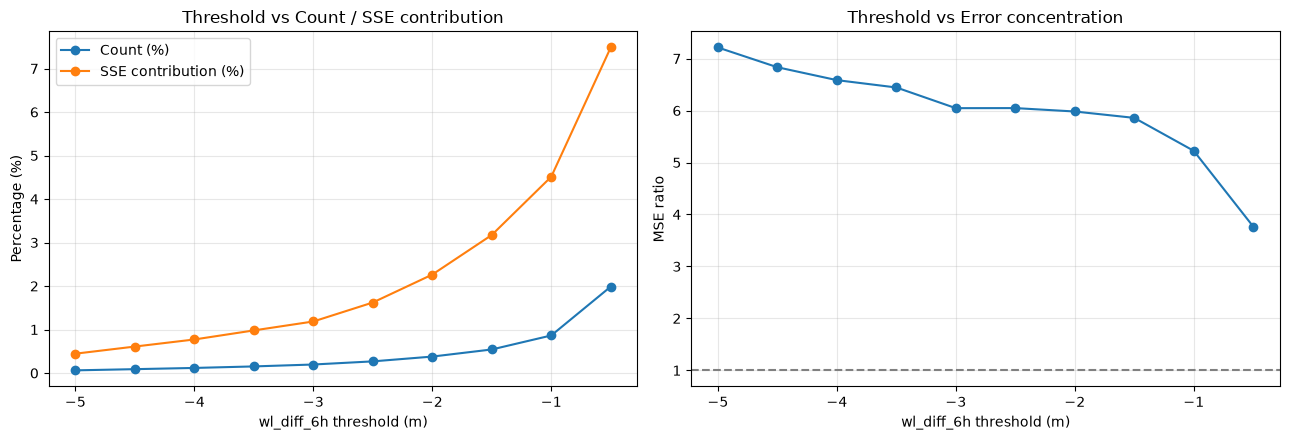

In [55]:
# ============================================================
# 3-2. 계측오류 의심 임계값별 RMSE 및 SSE 기여율 비교
# ============================================================

thresholds = [-0.5, -1, -1.5, -2, -2.5, -3, -3.5, -4, -4.5, -5]

total_count = train_kf_oof['resid_sq'].count()
total_sse = train_kf_oof['resid_sq'].sum()

meas_error_results = []

for threshold in thresholds:

    cond_meas_error = train_kf_oof['wl_diff_6h'] < threshold
    error_data = train_kf_oof.loc[cond_meas_error, 'resid_sq']

    count = error_data.count()
    sse = error_data.sum()
    mse = error_data.mean()

    meas_error_results.append({
        'threshold': threshold,
        'count': count,
        'count_pct(%)': count / total_count * 100,
        'sse': sse,
        'sse_contribution_pct(%)': sse / total_sse * 100,
        'rmse': np.sqrt(mse),
        'error_concentration': (
            (sse / total_sse) / (count / total_count)
            if count > 0 else np.nan
        )
    })

meas_error_threshold = pd.DataFrame(meas_error_results)

display(meas_error_threshold)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. 임계값에 따른 count 비율과 SSE 기여율
axes[0].plot(
    meas_error_threshold['threshold'],
    meas_error_threshold['count_pct(%)'],
    marker='o', label='Count (%)'
)

axes[0].plot(
    meas_error_threshold['threshold'],
    meas_error_threshold['sse_contribution_pct(%)'],
    marker='o', label='SSE contribution (%)'
)

axes[0].set_xlabel('wl_diff_6h threshold (m)')
axes[0].set_ylabel('Percentage (%)')
axes[0].set_title('Threshold vs Count / SSE contribution')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. 임계값에 따른 오차 집중 배율
axes[1].plot(
    meas_error_threshold['threshold'],
    meas_error_threshold['error_concentration'],
    marker='o'
)

axes[1].axhline(1, linestyle='--', color='gray')
axes[1].set_xlabel('wl_diff_6h threshold (m)')
axes[1].set_ylabel('MSE ratio')
axes[1].set_title('Threshold vs Error concentration')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [57]:
# ============================================================
# 3-11. 사상(event_id)별 전체 SSE 및 RMSE 분석
# ============================================================
# 분석 목적
# - 전체 예측오차가 특정 수위변동 사상에 집중되는지 확인
# - 사상별 SSE 기여율을 통해 전체 RMSE에 미치는 영향 파악
# - 사상별 RMSE를 통해 관측치 수에 따른 영향을 구분
#
# 분석 방법
# - event_id별 관측치 수, 관측소 수, SSE, RMSE 계산
# - 전체 SSE 대비 사상별 기여율 및 누적 기여율 산출
# - SSE가 큰 사상부터 정렬하여 상위 20개 확인
# ============================================================

# 1. 전체 SSE 계산
total_sse = train_kf_oof['resid_sq'].sum()

# 2. event_id별 오차 집계
event_error = (
    train_kf_oof
    .groupby('event_id')
    .agg(
        count=('resid_sq', 'size'),
        station_count=('station_id', 'nunique'),
        sse=('resid_sq', 'sum'),
        mse=('resid_sq', 'mean')
    )
)

# 3. RMSE 및 SSE 기여율 계산
event_error['rmse'] = np.sqrt(event_error['mse'])

event_error['sse_pct'] = (
    event_error['sse'] / total_sse * 100
)

# 4. SSE 내림차순 정렬 및 누적 기여율 계산
event_error = event_error.sort_values('sse', ascending=False)

event_error['cumulative_sse_pct'] = (
    event_error['sse_pct'].cumsum()
)

# 5. SSE 상위 20개 사상 확인
display(event_error.head(20))

,count,station_count,sse,mse,rmse,sse_pct,cumulative_sse_pct
event_id,,,,,,,
98,71567,464,7696.683084,0.107545,0.327941,23.038284,23.038284
90,24970,465,3795.923741,0.152019,0.389897,11.362241,34.400526
35,19967,465,3318.868811,0.166218,0.407698,9.934285,44.334811
97,7408,463,3212.073848,0.433595,0.658480,9.614618,53.949429
3,18059,464,2627.781318,0.145511,0.381459,7.865671,61.815100
89,25289,464,2286.620361,0.090420,0.300698,6.844482,68.659582
28,28931,465,939.044562,0.032458,0.180161,2.810818,71.470400
96,19530,465,810.445352,0.041497,0.203709,2.425885,73.896286
7,18192,465,786.295414,0.043222,0.207899,2.353598,76.249883


In [58]:
# ============================================================
# 3-12. 잔차제곱 상위 1% 데이터의 사상(event_id)별 집중도 분석
# ============================================================
# 분석 목적
# - 극단적인 예측오차가 특정 사상에서 반복적으로 발생하는지 확인
# - 고잔차가 동일 사상의 여러 관측소에서 발생하는지 확인
# - 상위 고잔차 사상이 전체 SSE에 미치는 영향 파악
#
# 분석 방법
# - 전체 OOF 데이터에서 잔차제곱 상위 1% 추출
# - event_id별 고잔차 발생 횟수, 관측소 수, SSE 계산
# - 전체 SSE 대비 기여율 및 누적 기여율 산출
# - 고잔차 SSE가 큰 사상부터 상위 20개 확인
# ============================================================

# 1. 잔차제곱 상위 1% 기준값 계산
threshold = train_kf_oof['resid_sq'].quantile(0.99)

# 2. 잔차제곱 상위 1% 데이터 추출
high_error = train_kf_oof.loc[
    train_kf_oof['resid_sq'] >= threshold
].copy()

# 3. event_id별 고잔차 집계
high_error_event = (
    high_error
    .groupby('event_id')
    .agg(
        high_error_count=('resid_sq', 'size'),
        station_count=('station_id', 'nunique'),
        high_error_sse=('resid_sq', 'sum')
    )
)

# 4. 전체 SSE 대비 고잔차 기여율 계산
high_error_event['total_sse_pct'] = (
    high_error_event['high_error_sse'] / total_sse * 100
)

# 5. 고잔차 SSE 내림차순 정렬 및 누적 기여율 계산
high_error_event = (
    high_error_event
    .sort_values('high_error_sse', ascending=False)
)

high_error_event['cumulative_sse_pct'] = (
    high_error_event['total_sse_pct'].cumsum()
)

# 6. 고잔차 SSE 상위 20개 사상 확인
display(high_error_event.head(20))

,high_error_count,station_count,high_error_sse,total_sse_pct,cumulative_sse_pct
event_id,,,,,
98,1680,274,4384.874835,13.125134,13.125134
90,555,133,3041.101441,9.102851,22.227985
97,791,195,2563.307737,7.672683,29.900668
35,763,160,2429.560253,7.272341,37.173009
3,567,134,1771.450202,5.302437,42.475445
89,353,79,1537.437550,4.601972,47.077418
67,154,60,446.279567,1.335837,48.413255
28,165,51,383.057952,1.146598,49.559852
29,107,33,317.570931,0.950577,50.510429
